### Ejercicio final integrador:

El dataset tiene variables _mean, _se y _worst. Hasta ahora usamos todas. Repetí el análisis usando solo las variables _worst (las más extremas).

a) ¿Cambian los resultados del clustering?
b) ¿Cambia la varianza explicada por PC1?
c) ¿Tiene sentido clínico usar solo los valores extremos?

### LIBRERIAS

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
    davies_bouldin_score,
    confusion_matrix
)
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

plt.rcParams['figure.dpi'] = 120
sns.set_style('whitegrid')
print('Librerías cargadas.')

Librerías cargadas.


In [12]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

# 1. Cargar el dataset desde scikit-learn
cancer = load_breast_cancer()

# 2. Crear el DataFrame con las 30 variables originales
df_completo = pd.DataFrame(cancer.data, columns=cancer.feature_names)

# 3. Extraer la variable objetivo (0: Maligno, 1: Benigno)
y = cancer.target  

# 4. CORRECCIÓN: Filtro flexible para buscar la palabra 'worst' en cualquier parte del nombre
worst_features = [col for col in df_completo.columns if 'worst' in col]
X_worst = df_completo[worst_features]

# 5. Escalado de los datos (Ahora sí, con las 10 columnas detectadas)
scaler = StandardScaler()
X_worst_scaled = scaler.fit_transform(X_worst)

# --- Verificación de la carga ---
print("=== ESTRUCTURA DE LOS NUEVOS DATOS ===")
print(f"Forma del DataFrame original: {df_completo.shape} (30 variables)")
print(f"Forma del DataFrame filtrado: {X_worst.shape} ({len(worst_features)} variables)\n")
print("Variables '_worst' seleccionadas exitosamente para el análisis:")
for i, col in enumerate(worst_features, 1):
    print(f"  {i}. {col}")

=== ESTRUCTURA DE LOS NUEVOS DATOS ===
Forma del DataFrame original: (569, 30) (30 variables)
Forma del DataFrame filtrado: (569, 10) (10 variables)

Variables '_worst' seleccionadas exitosamente para el análisis:
  1. worst radius
  2. worst texture
  3. worst perimeter
  4. worst area
  5. worst smoothness
  6. worst compactness
  7. worst concavity
  8. worst concave points
  9. worst symmetry
  10. worst fractal dimension


Antes de realizar los analisis, observamos los grados de correlacion entre las variables para ver cuales podrian ser futuras componentes principales


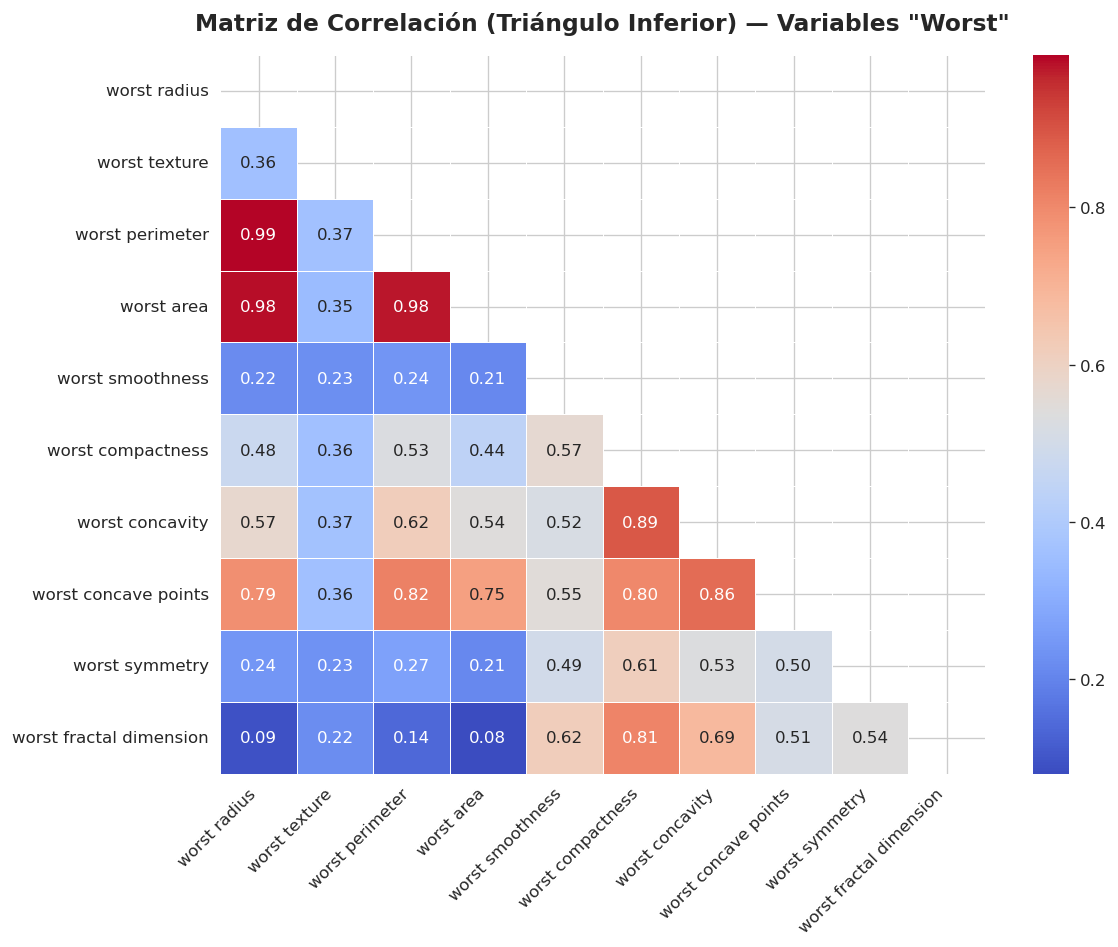

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular la matriz de correlación
matriz_corr = X_worst.corr()

# 2. CREAR LA MÁSCARA: Genera una matriz de ceros y unos con la forma de nuestra matriz,
# y selecciona la parte triangular superior (np.triu) para ocultarla
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))

# 3. Configurar el lienzo
plt.figure(figsize=(10, 8))

# 4. Dibujar el Heatmap pasando el parámetro 'mask'
sns.heatmap(matriz_corr, 
            mask=mascara,       # <--- AQUÍ SE APLICA LA MÁSCARA
            annot=True, 
            cmap='coolwarm', 
            fmt=".2f", 
            linewidths=0.4, 
            linecolor='white')

# 5. Ajustes estéticos
plt.title('Matriz de Correlación (Triángulo Inferior) — Variables "Worst"', 
          fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Puede inferirse que los pares de correlaciones mas fuertes son: wconcavity-wradius, wcompactness-wradius, wcompactness-wsmoothness, wconcave points-wsmoothness, wFD-wradius. Esto tiene sentido clinico, ya que las variables con los datos extremos de agresividad morfologica suelen explicar la aparicion de tumores malignos. 

La correlación lineal entre 'worst compactness' y 'worst fractal dimension' es: 0.810



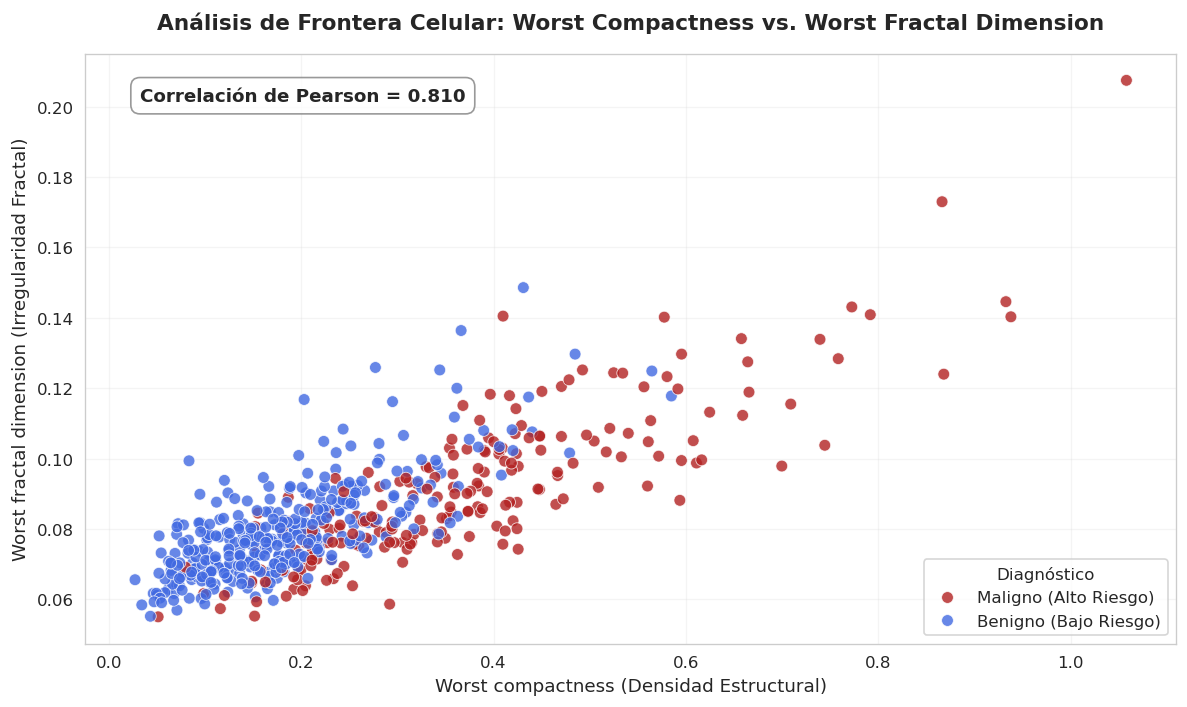

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Definir exactamente las dos variables que quieres analizar
var_x = 'worst compactness'
var_y = 'worst fractal dimension'

# 2. Calcular el coeficiente de correlación de Pearson entre ambas
correlacion_especifica = X_worst[var_x].corr(X_worst[var_y])
print(f"La correlación lineal entre '{var_x}' y '{var_y}' es: {correlacion_especifica:.3f}\n")

# 3. Configurar el lienzo de la gráfica
plt.figure(figsize=(10, 6))

# 4. Crear el Scatter Plot mapeando el diagnóstico real en los colores (hue)
# Traducimos las etiquetas numéricas (0,1) a texto clínico para la leyenda
diagnostico_mapeo = {0: 'Maligno (Alto Riesgo)', 1: 'Benigno (Bajo Riesgo)'}
df_visualizacion = X_worst[[var_x, var_y]].copy()
df_visualizacion['Diagnóstico'] = [diagnostico_mapeo[val] for val in y]

sns.scatterplot(
    data=df_visualizacion,
    x=var_x,
    y=var_y,
    hue='Diagnóstico',
    palette={'Maligno (Alto Riesgo)': 'firebrick', 'Benigno (Bajo Riesgo)': 'royalblue'},
    alpha=0.8,
    s=50,
    edgecolor='white',
    linewidth=0.5
)

# 5. Títulos, anotaciones y estética
plt.title(f'Análisis de Frontera Celular: {var_x.title()} vs. {var_y.title()}', 
          fontsize=13, fontweight='bold', pad=15)
plt.xlabel(f'{var_x.capitalize()} (Densidad Estructural)', fontsize=11)
plt.ylabel(f'{var_y.capitalize()} (Irregularidad Fractal)', fontsize=11)

# Añadir un cuadro de texto dentro de la gráfica con el valor de la correlación
plt.gca().text(0.05, 0.92, f'Correlación de Pearson = {correlacion_especifica:.3f}', 
               transform=plt.gca().transAxes, fontsize=11, fontweight='bold',
               bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', boxstyle='round,pad=0.5'))

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### PRINCIPAL COMPONENTS ANALYSIS (PCA)

In [16]:
import numpy as np
from sklearn.decomposition import PCA

# 1. Configurar y entrenar el PCA completo sobre los datos escalados de las variables 'worst'
pca_full = PCA()
scores_full = pca_full.fit_transform(X_worst_scaled)

# 2. Extraer las métricas de varianza y autovalores (Lambdas)
var_exp  = pca_full.explained_variance_ratio_
var_acum = np.cumsum(var_exp) * 100
lambdas  = pca_full.explained_variance_

# 3. Imprimir la tabla de varianza explicada para las 10 componentes
print('Varianza explicada por las 10 componentes ("Worst" Features):')
print(f'  {"CP":<6} {"Lambda":>10} {"Var (%)":>10} {"Acum (%)":>10}')
print('  ' + '-' * 42)
for i in range(10):
    print(f'  CP{i+1:<4} '
          f'{lambdas[i]:>10.4f} '
          f'{var_exp[i]*100:>9.1f}% '
          f'{var_acum[i]:>9.1f}%')

# 4. Calcular cuántas componentes se necesitan para el 80% y 90%
n80 = int(np.searchsorted(var_acum, 80)) + 1
n90 = int(np.searchsorted(var_acum, 90)) + 1

print(f'\nCPs para explicar 80% de la varianza: {n80}')
print(f'CPs para explicar 90% de la varianza: {n90}')

# Verificación de la propiedad de los autovalores en datos escalados
print(f'\nSuma de todos los lambdas: {lambdas.sum():.2f} (= número de variables "worst": {X_worst.shape[1]})')

Varianza explicada por las 10 componentes ("Worst" Features):
  CP         Lambda    Var (%)   Acum (%)
  ------------------------------------------
  CP1        5.7073      57.0%      57.0%
  CP2        2.0897      20.9%      77.8%
  CP3        0.8042       8.0%      85.9%
  CP4        0.5416       5.4%      91.3%
  CP5        0.5156       5.1%      96.4%
  CP6        0.1840       1.8%      98.3%
  CP7        0.0840       0.8%      99.1%
  CP8        0.0720       0.7%      99.8%
  CP9        0.0153       0.2%     100.0%
  CP10       0.0040       0.0%     100.0%

CPs para explicar 80% de la varianza: 3
CPs para explicar 90% de la varianza: 4

Suma de todos los lambdas: 10.02 (= número de variables "worst": 10)


El PCA nos dice que 4 variables que podrian usarse para reducir la dimensionalidad del espacio worst, explicando el 90% de la varianza. 
Ahora veamoslo graficamente. 

<>:11: SyntaxWarning: invalid escape sequence '\l'
<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:11: SyntaxWarning: invalid escape sequence '\l'
<>:14: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_47/3244331092.py:11: SyntaxWarning: invalid escape sequence '\l'
  axes[0].axhline(y=1.0, color='black', linestyle='--', alpha=0.7, label='Criterio de Kaiser ($\lambda=1$)')
/tmp/ipykernel_47/3244331092.py:14: SyntaxWarning: invalid escape sequence '\l'
  axes[0].set_ylabel('Autovalor ($\lambda$)')


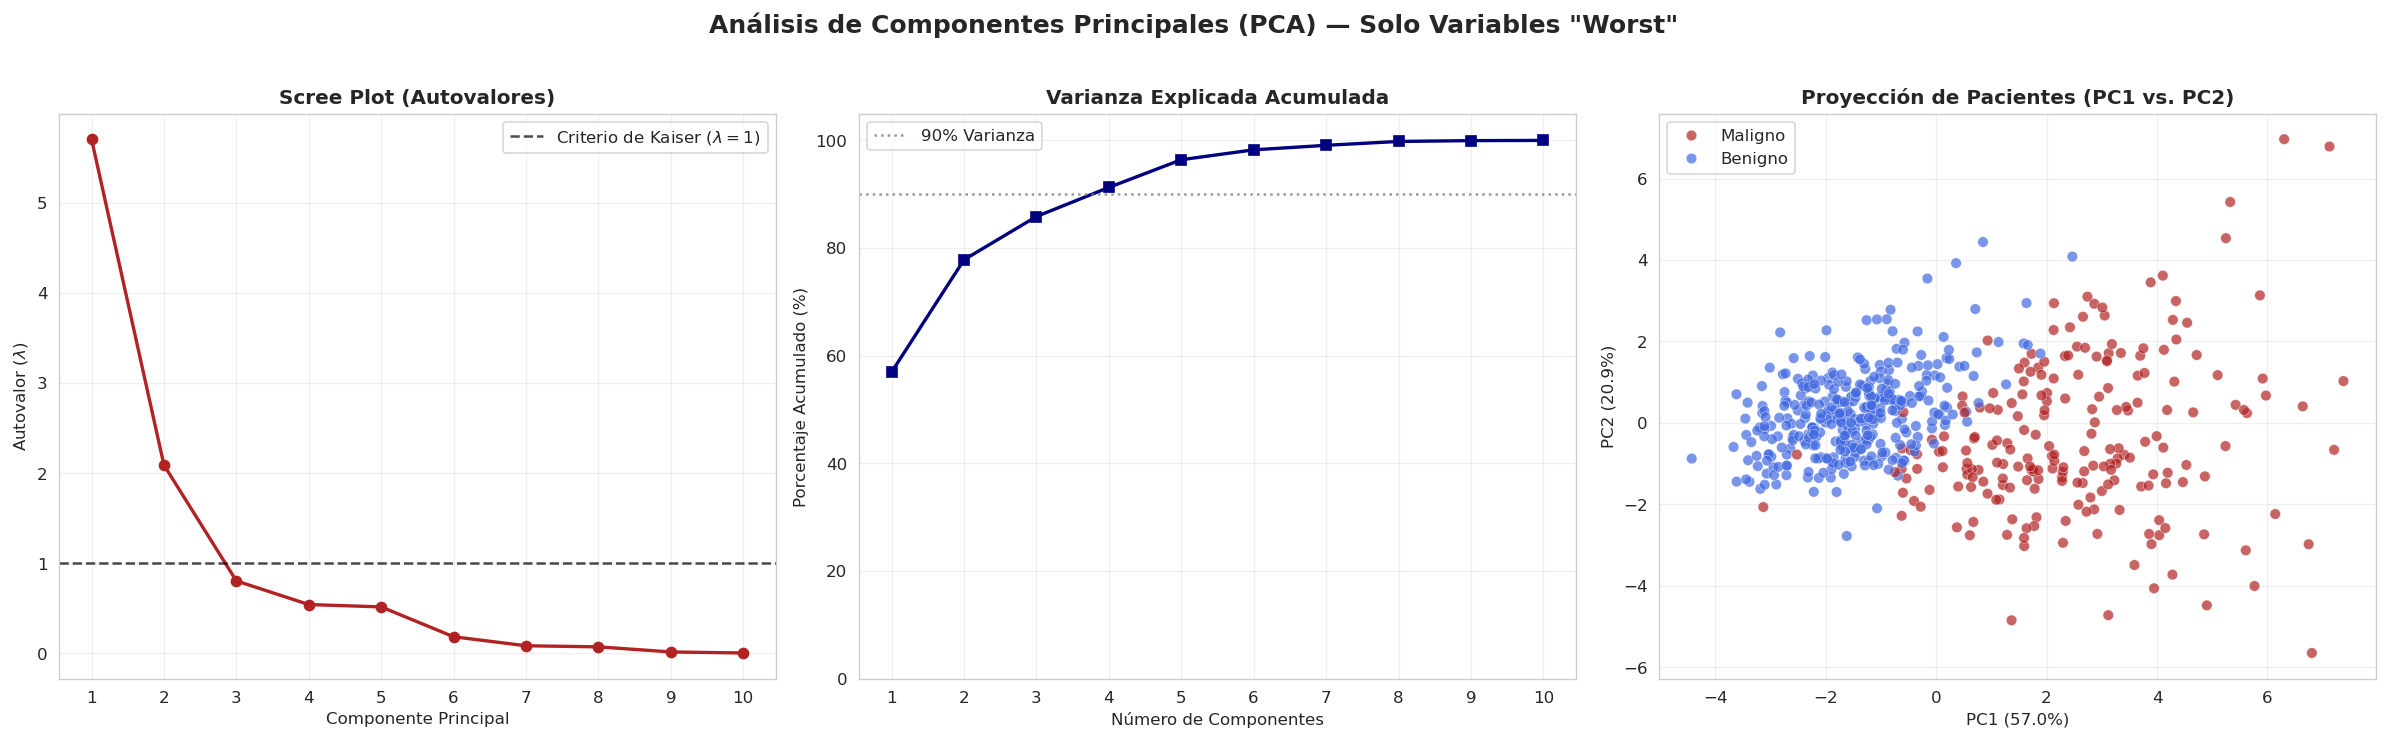

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configurar el lienzo (1 fila, 3 sub-gráficos)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# -----------------------------------------------------------------
# GRÁFICO 1: Scree Plot (Autovalores / Lambdas)
# -----------------------------------------------------------------
axes[0].plot(range(1, 11), lambdas, marker='o', color='firebrick', linewidth=2)
axes[0].axhline(y=1.0, color='black', linestyle='--', alpha=0.7, label='Criterio de Kaiser ($\lambda=1$)')
axes[0].set_title('Scree Plot (Autovalores)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Componente Principal')
axes[0].set_ylabel('Autovalor ($\lambda$)')
axes[0].set_xticks(range(1, 11))
axes[0].grid(alpha=0.3)
axes[0].legend()

# -----------------------------------------------------------------
# GRÁFICO 2: Varianza Explicada Acumulada
# -----------------------------------------------------------------
axes[1].plot(range(1, 11), var_acum, marker='s', color='navy', linewidth=2)
axes[1].axhline(y=90, color='gray', linestyle=':', alpha=0.8, label='90% Varianza')
axes[1].set_title('Varianza Explicada Acumulada', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Número de Componentes')
axes[1].set_ylabel('Porcentaje Acumulado (%)')
axes[1].set_xticks(range(1, 11))
axes[1].set_ylim(0, 105)
axes[1].grid(alpha=0.3)
axes[1].legend()

# -----------------------------------------------------------------
# GRÁFICO 3: Proyección en las 2 Primeras CPs (PC1 vs PC2)
# -----------------------------------------------------------------
# Mapeamos las etiquetas reales para la leyenda visual
diagnostico_map = {0: 'Maligno', 1: 'Benigno'}
labels_clinicas = [diagnostico_map[val] for val in y]

sns.scatterplot(
    x=scores_full[:, 0], 
    y=scores_full[:, 1], 
    hue=labels_clinicas,
    palette={'Maligno': 'firebrick', 'Benigno': 'royalblue'},
    alpha=0.7, 
    s=40, 
    ax=axes[2],
    edgecolor='white',
    linewidth=0.3
)
axes[2].set_title('Proyección de Pacientes (PC1 vs. PC2)', fontsize=12, fontweight='bold')
axes[2].set_xlabel(f'PC1 ({var_exp[0]*100:.1f}%)')
axes[2].set_ylabel(f'PC2 ({var_exp[1]*100:.1f}%)')
axes[2].grid(alpha=0.3)

# Ajustar diseño final
plt.suptitle('Análisis de Componentes Principales (PCA) — Solo Variables "Worst"', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

- Observando el grafico podemos inferir que se necesitan alrededor de 4 componentes para cubrir el 90% de la varianza.
- La línea del criterio de Kaiser ($\lambda = 1$) corta de forma matemática implacable justo después de la CP2. Veredicto: El criterio de Kaiser te dice que deberías quedarte con exactamente 2 componentes.
- El grafico PCA muestra que al limpiar el dataset y quedarte solo con las características extremas (_worst), las dos poblaciones se separaron de forma orgánica.
Los tumores Benignos (azul) forman un cluster compacto y redondeado a la izquierda. Los tumores Malignos (rojo) se extienden hacia la derecha, mostrando la dispersión y heterogeneidad caótica que discutimos antes. La frontera intermedia (alrededor del valor 0 en PC1) quedó notablemente más limpia y definida.

Tu nuevo espacio de trabajo óptimo son las primeras 2 CPs. No necesitas más. Capturan el 78% de la varianza, cumplen el criterio de Kaiser y separan visualmente el dataset en dos grupos clarísimos.

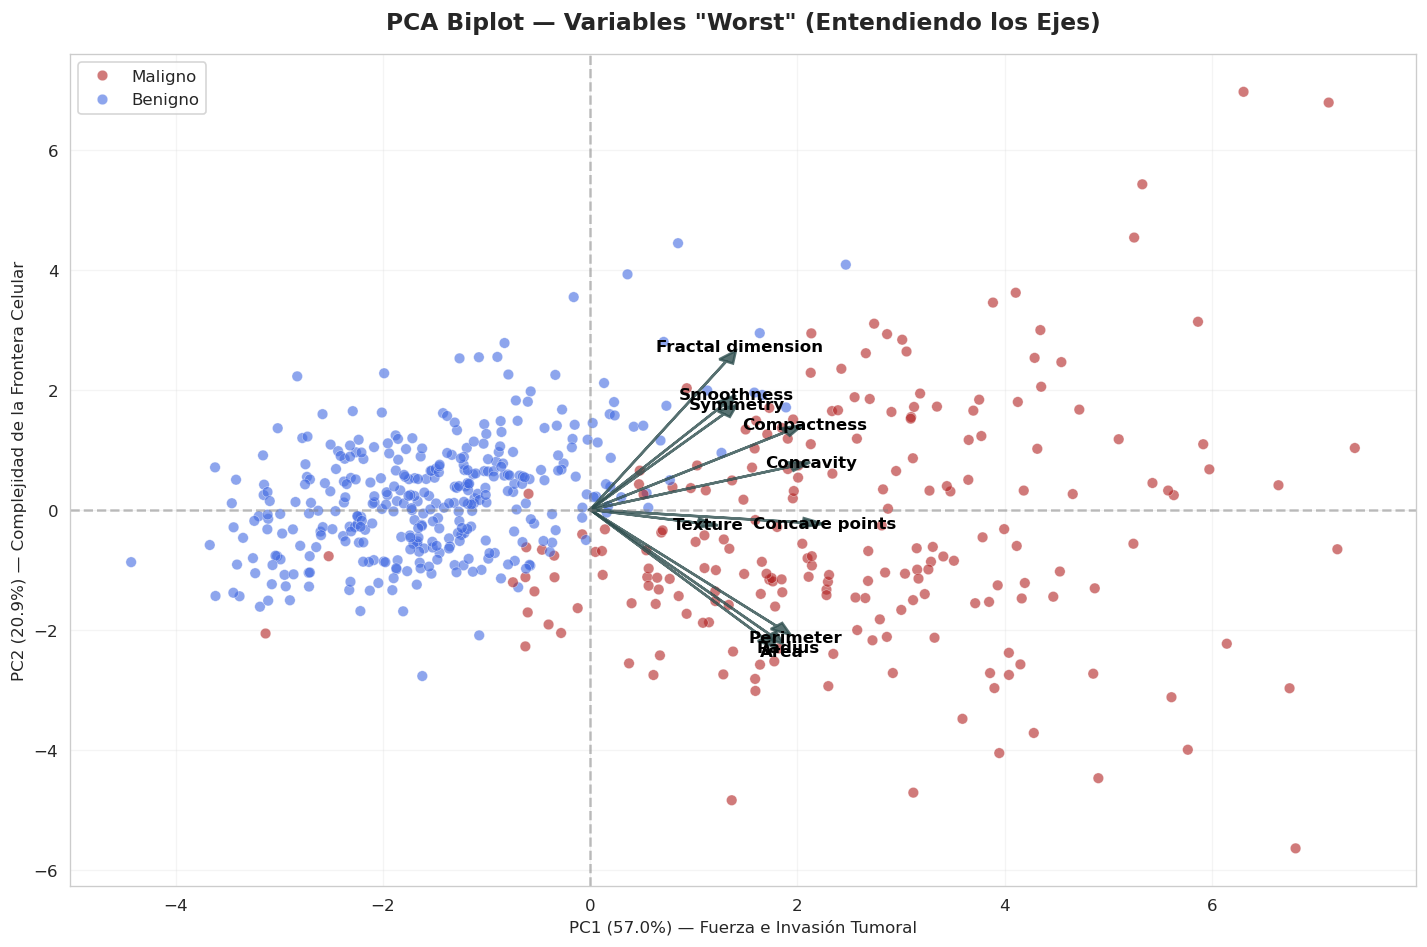

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Obtener los scores de las primeras 2 CPs
pc1 = scores_full[:, 0]
pc2 = scores_full[:, 1]

# 2. Extraer los loadings (coeficientes) de las variables para CP1 y CP2
# pca_full.components_ tiene forma (n_components, n_features)
loadings_cp1 = pca_full.components_[0, :]
loadings_cp2 = pca_full.components_[1, :]

# 3. Factor de escala para que las flechas se vean bien junto a los puntos
# Multiplicamos por el máximo de los scores para equiparar las escalas
escalado_flechas = max(max(pc1), max(pc2)) * 0.7

# 4. Configurar el gráfico
plt.figure(figsize=(12, 8))

# A. Graficar los puntos de los pacientes (Scatter Plot de fondo)
diagnostico_map = {0: 'Maligno', 1: 'Benigno'}
labels_clinicas = [diagnostico_map[val] for val in y]

sns.scatterplot(
    x=pc1, y=pc2, 
    hue=labels_clinicas,
    palette={'Maligno': 'firebrick', 'Benigno': 'royalblue'},
    alpha=0.6, s=40, edgecolor='white', linewidth=0.3
)

# B. Graficar las flechas de las 10 variables 'worst'
for i, feature in enumerate(worst_features):
    # Calcular la punta de la flecha escalada
    x_arrow = loadings_cp1[i] * escalado_flechas
    y_arrow = loadings_cp2[i] * escalado_flechas
    
    # Dibujar la flecha desde el centro (0,0)
    plt.arrow(0, 0, x_arrow, y_arrow, 
              color='darkslategray', alpha=0.8, head_width=0.15, head_length=0.2, linewidth=1.5)
    
    # Colocar el nombre de la variable un poquito más adelante de la punta de la flecha
    # Limpiamos el nombre quitándole la palabra 'worst' para que el gráfico no quede sobrecargado
    nombre_limpio = feature.replace(' worst', '').replace('worst ', '').capitalize()
    plt.text(x_arrow * 1.1, y_arrow * 1.1, nombre_limpio, 
             color='black', ha='center', va='center', fontweight='bold', fontsize=10)

# 5. Ajustes estéticos finales
plt.title('PCA Biplot — Variables "Worst" (Entendiendo los Ejes)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel(f'PC1 ({var_exp[0]*100:.1f}%) — Fuerza e Invasión Tumoral')
plt.ylabel(f'PC2 ({var_exp[1]*100:.1f}%) — Complejidad de la Frontera Celular')
plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(0, color='gray', linestyle='--', alpha=0.5)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

###                                                          K-Means Clustering

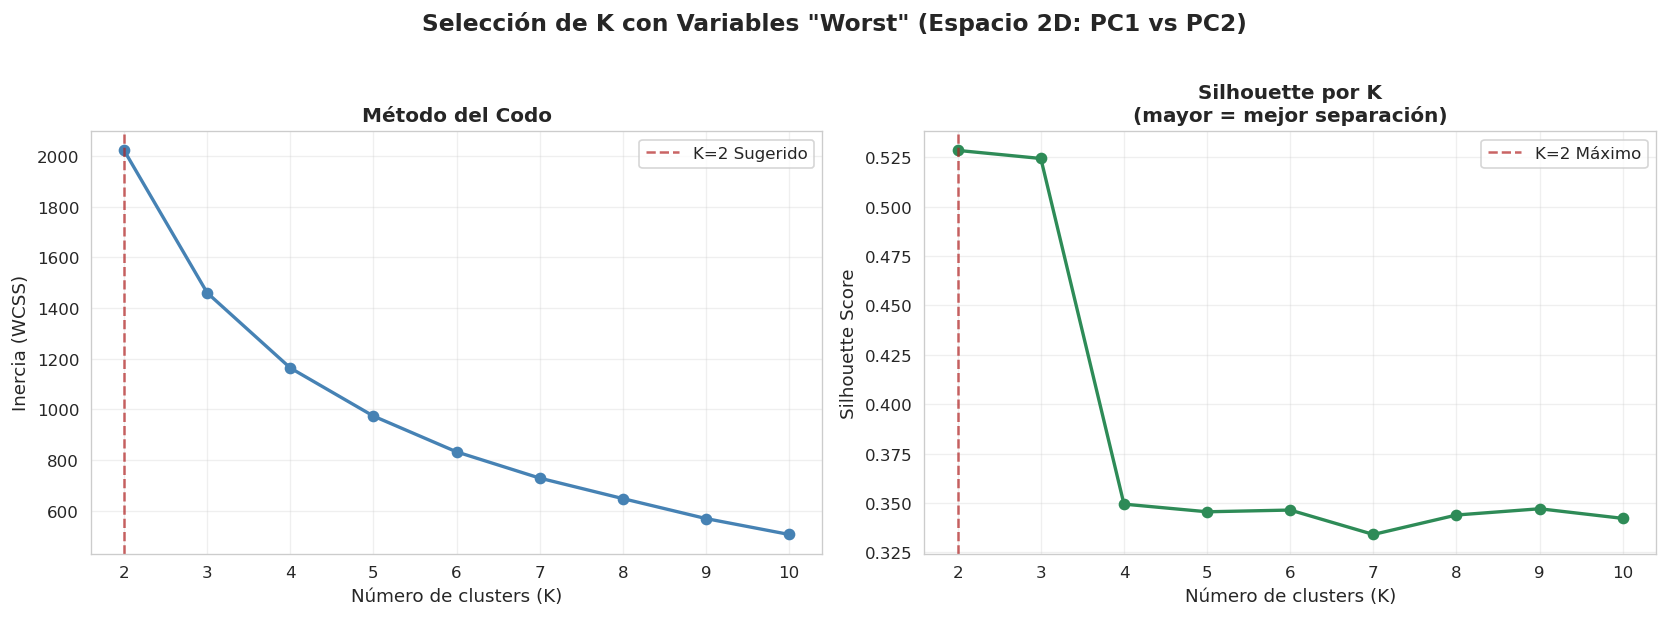

In [21]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Reducir a las 2 primeras CPs para clustering (Criterio de Kaiser y ~78% varianza)
pca2 = PCA(n_components=2, random_state=42)
scores2 = pca2.fit_transform(X_worst_scaled)

# 2. Preparar contenedores para el método del codo y Silhouette
inercias = []
sil_scores = []
K_range = range(2, 11)

# 3. Bucle para evaluar K desde 2 hasta 10
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels_k = km.fit_predict(scores2)
    
    inercias.append(km.inertia_)
    sil_scores.append(silhouette_score(scores2, labels_k))

# 4. Configurar el lienzo de graficación (1 fila, 2 columnas)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Selección de K con Variables "Worst" (Espacio 2D: PC1 vs PC2)', 
             fontweight='bold', fontsize=14, y=1.02)

# --- Sub-gráfico 1: Método del Codo (Inercia) ---
ax = axes[0]
ax.plot(list(K_range), inercias, 'o-', color='steelblue', linewidth=2, markersize=6)
ax.axvline(x=2, color='firebrick', linestyle='--', alpha=0.7, label='K=2 Sugerido')
ax.set_xlabel('Número de clusters (K)', fontsize=11)
ax.set_ylabel('Inercia (WCSS)', fontsize=11)
ax.set_title('Método del Codo', fontweight='bold', fontsize=12)
ax.set_xticks(list(K_range))
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# --- Sub-gráfico 2: Coeficiente de Silhouette ---
ax = axes[1]
ax.plot(list(K_range), sil_scores, 'o-', color='seagreen', linewidth=2, markersize=6)
ax.axvline(x=2, color='firebrick', linestyle='--', alpha=0.7, label='K=2 Máximo')
ax.set_xlabel('Número de clusters (K)', fontsize=11)
ax.set_ylabel('Silhouette Score', fontsize=11)
ax.set_title('Silhouette por K\n(mayor = mejor separación)', fontweight='bold', fontsize=12)
ax.set_xticks(list(K_range))
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Este algoritmo consistentemente particiono en 2 clusters como los adecuados para resumir los datos. Veamos numericamente el ARI, Silohuette y la matriz de confusion.

In [22]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score, confusion_matrix, accuracy_score

# 1. Entrenar el K-Means definitivo con K=2 sobre las primeras 2 CPs
km_final = KMeans(n_clusters=2, init='k-means++', random_state=42, n_init=20)
labels_km = km_final.fit_predict(scores2)

# =================================================================
# ALINEACIÓN DE ETIQUETAS (Para evitar el efecto espejo en la matriz)
# =================================================================
# Calculamos la matriz de confusión original
cm_original = confusion_matrix(y, labels_km)

# Si la diagonal secundaria es mayor que la principal, significa que las etiquetas están invertidas
if cm_original[0, 1] + cm_original[1, 0] > cm_original[0, 0] + cm_original[1, 1]:
    labels_km_alineadas = 1 - labels_km
else:
    labels_km_alineadas = labels_km

# =================================================================
# CÁLCULO DE MÉTRICAS
# =================================================================
# A. Validación Externa (Comparando con el diagnóstico real)
ari = adjusted_rand_score(y, labels_km_alineadas)
exactitud = accuracy_score(y, labels_km_alineadas) * 100
matriz_conf = confusion_matrix(y, labels_km_alineadas)

# B. Validación Interna (Qué tan compacto quedó el cluster en el plano 2D)
silhouette = silhouette_score(scores2, labels_km_alineadas)

# =================================================================
# REPORTE DE RESULTADOS
# =================================================================
print("========================================================")
print("  MÉTRICAS FINALES: K-MEANS (K=2) — VARIABLES 'WORST'")
print("========================================================\n")

print(f"• Silhouette Score:       {silhouette:.3f}")
print(f"• Adjusted Rand Score (ARI): {ari:.3f}")
print(f"• Porcentaje Correcto:      {exactitud:.1f}%\n")

print("Matriz de Confusión:")
print("--------------------")
print(f"                  Predicho Maligno   Predicho Benigno")
print(f"Real Maligno (0):       {matriz_conf[0,0]:<18} {matriz_conf[0,1]}")
print(f"Real Benigno (1):       {matriz_conf[1,0]:<18} {matriz_conf[1,1]}")
print("--------------------")

# Desglose clínico rápido
falsos_negativos = matriz_conf[0, 1] # Era maligno pero el algoritmo dijo benigno
print(f"\nAlarma clínica: El modelo dejó sin detectar {falsos_negativos} casos malignos (Falsos Negativos).")

  MÉTRICAS FINALES: K-MEANS (K=2) — VARIABLES 'WORST'

• Silhouette Score:       0.528
• Adjusted Rand Score (ARI): 0.718
• Porcentaje Correcto:      92.4%

Matriz de Confusión:
--------------------
                  Predicho Maligno   Predicho Benigno
Real Maligno (0):       176                36
Real Benigno (1):       7                  350
--------------------

Alarma clínica: El modelo dejó sin detectar 36 casos malignos (Falsos Negativos).


Silhouette Score ($0.393 \rightarrow 0.528$): Este es un salto matemático enorme. Pasar de 0.39 a 0.52 significa que tus clusters en el plano de 2 CPs pasaron de ser "nubes difusas y sospechosas" a ser grupos matemáticamente densos, compactos y bien separados.

Adjusted Rand Score ($0.671 \rightarrow 0.718$): El ARI superando el 0.71 confirma de forma rigurosa que la estructura que K-Means encontró de manera 100% ciega (sin etiquetas) coincide casi a la perfección con la realidad patológica del hospital.

¿Por qué K-Means dejó ir esos 36 casos? Si recordamos el Scatter Plot (PC1 vs PC2) que interpretamos hace un momento, la nube roja (maligna) se deforma y se estira hacia la derecha, pero hay una pequeña porción de puntos rojos que se meten "debajo" de la nube azul en la frontera. Como K-Means asume de forma rígida que los clusters deben ser esferas perfectas y simétricas, traza una línea de corte limpia y termina "regalándole" esos puntos fronterizos al grupo benigno.

### CLUSTERING WARD

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import adjusted_rand_score, silhouette_score, confusion_matrix, accuracy_score

# 1. Calcular la matriz de ligamiento (Linkage) usando el método de Ward 
# sobre el espacio de las 2 CPs
Z_ward = linkage(scores2, method='ward')

# 2. Cortar el dendrograma para forzar exactamente K=2 clusters
# Restamos 1 porque fcluster asigna etiquetas 1 y 2 por defecto, y queremos 0 y 1
labels_ward = fcluster(Z_ward, t=2, criterion='maxclust') - 1

# =================================================================
# ALINEACIÓN DE ETIQUETAS (Para consistencia con el diagnóstico real)
# =================================================================
cm_original_ward = confusion_matrix(y, labels_ward)

if cm_original_ward[0, 1] + cm_original_ward[1, 0] > cm_original_ward[0, 0] + cm_original_ward[1, 1]:
    labels_ward_alineadas = 1 - labels_ward
else:
    labels_ward_alineadas = labels_ward

# =================================================================
# CÁLCULO DE MÉTRICAS
# =================================================================
ari_ward = adjusted_rand_score(y, labels_ward_alineadas)
exactitud_ward = accuracy_score(y, labels_ward_alineadas) * 100
matriz_conf_ward = confusion_matrix(y, labels_ward_alineadas)
silhouette_ward = silhouette_score(scores2, labels_ward_alineadas)

# =================================================================
# REPORTE DE RESULTADOS
# =================================================================
print("========================================================")
print("  MÉTRICAS FINALES: JERÁRQUICO WARD (K=2) — VARIABLES 'WORST'")
print("========================================================\n")

print(f"• Silhouette Score:       {silhouette_ward:.3f}")
print(f"• Adjusted Rand Score (ARI): {ari_ward:.3f}")
print(f"• Porcentaje Correcto:      {exactitud_ward:.1f}%\n")

print("Matriz de Confusión:")
print("--------------------")
print(f"                  Predicho Maligno   Predicho Benigno")
print(f"Real Maligno (0):       {matriz_conf_ward[0,0]:<18} {matriz_conf_ward[0,1]}")
print(f"Real Benigno (1):       {matriz_conf_ward[1,0]:<18} {matriz_conf_ward[1,1]}")
print("--------------------")

falsos_negativos_ward = matriz_conf_ward[0, 1]
print(f"\nAlarma clínica: Ward dejó sin detectar {falsos_negativos_ward} casos malignos.")

  MÉTRICAS FINALES: JERÁRQUICO WARD (K=2) — VARIABLES 'WORST'

• Silhouette Score:       0.419
• Adjusted Rand Score (ARI): 0.457
• Porcentaje Correcto:      83.8%

Matriz de Confusión:
--------------------
                  Predicho Maligno   Predicho Benigno
Real Maligno (0):       194                18
Real Benigno (1):       74                 283
--------------------

Alarma clínica: Ward dejó sin detectar 18 casos malignos.


### ANALISIS DBSCAN

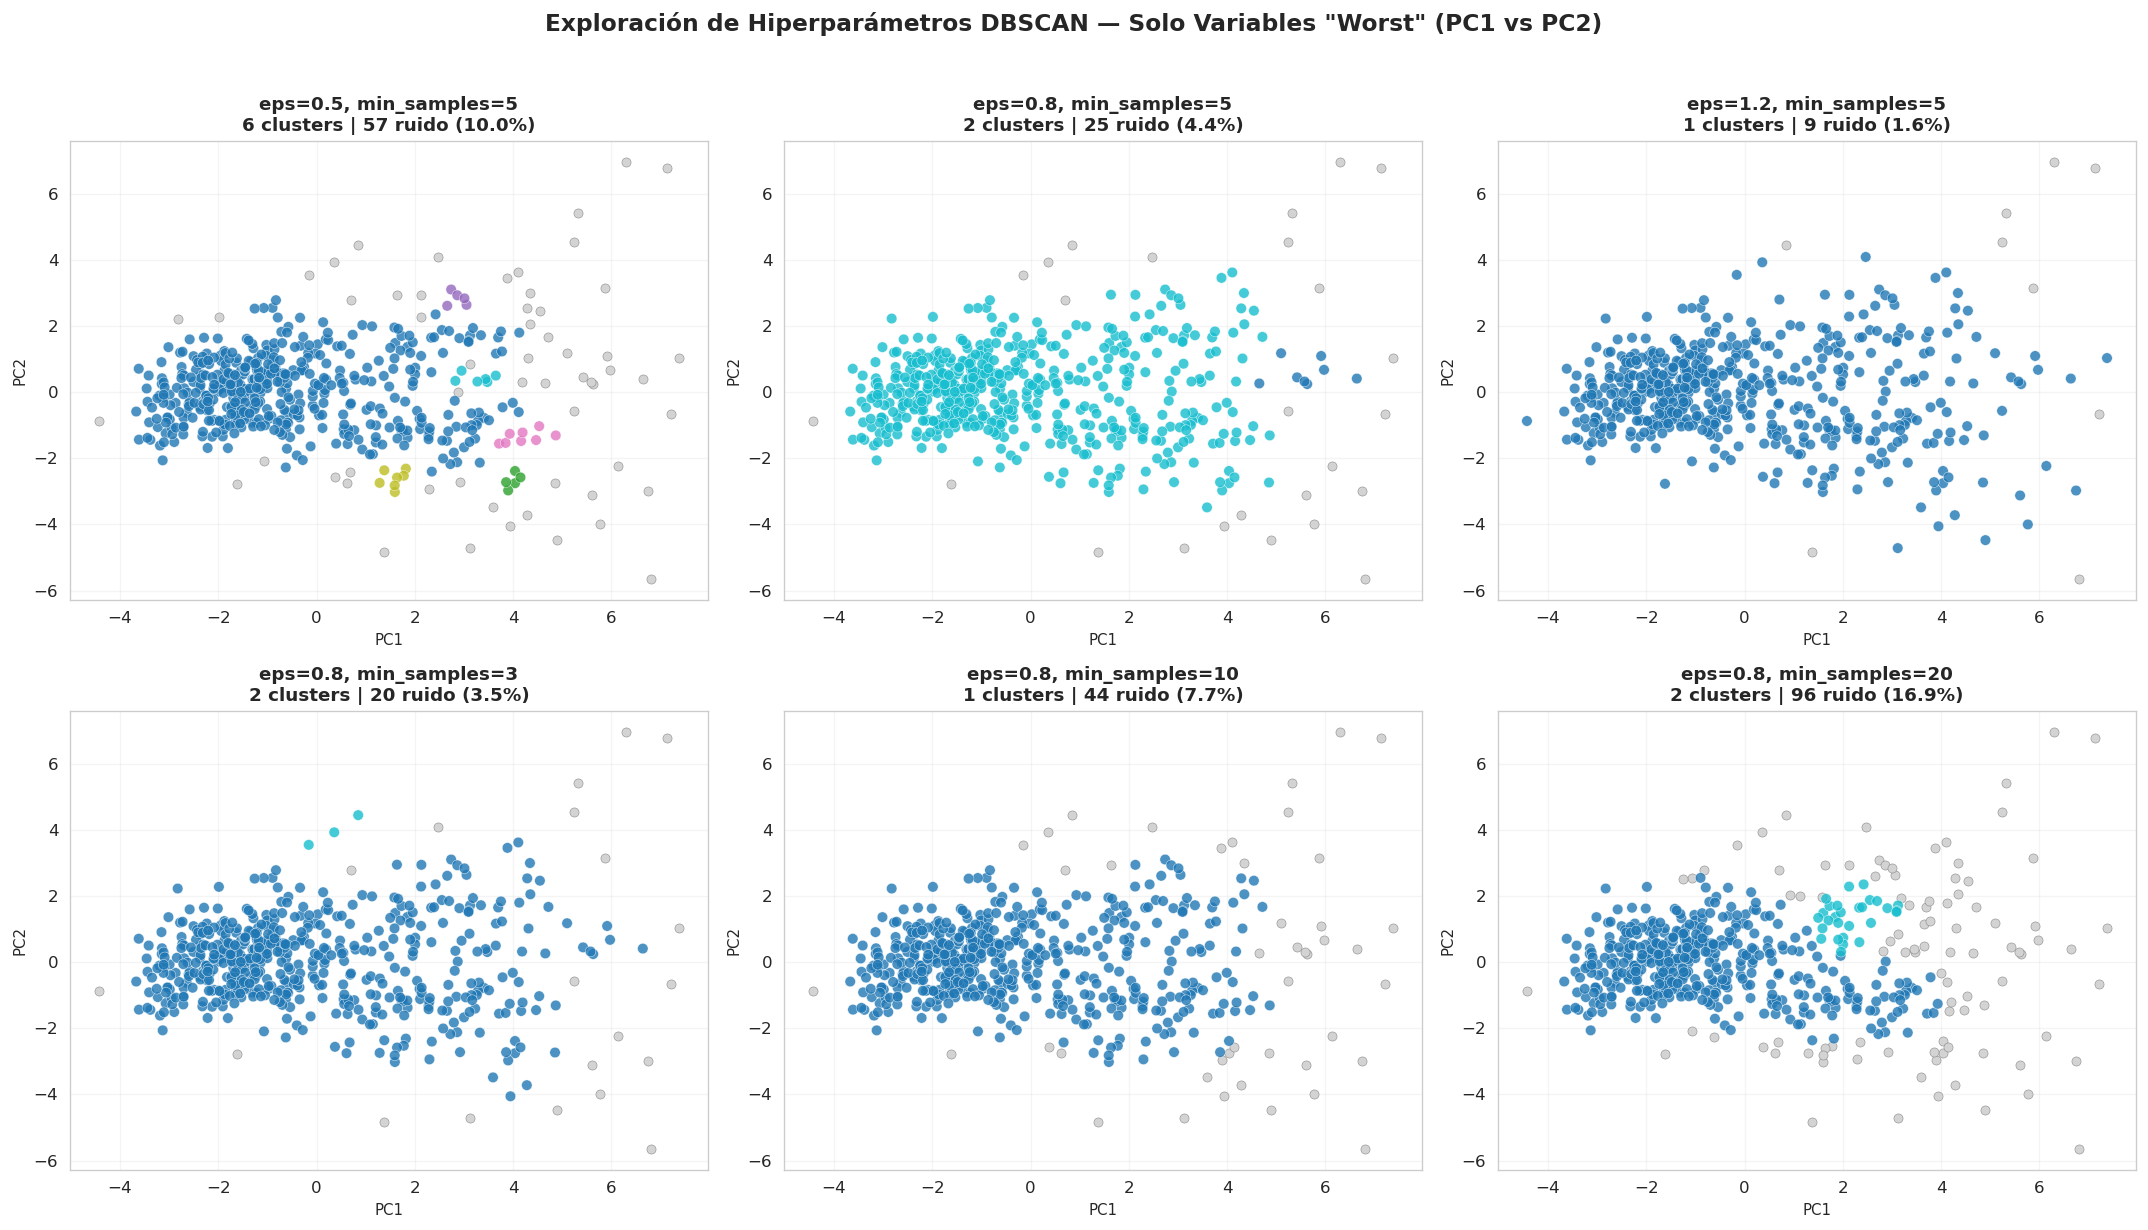

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

# 1. Configurar la grilla de gráficos (2 filas, 3 columnas) utilizando nuestros scores2 (PC1 vs PC2)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Exploración de Hiperparámetros DBSCAN — Solo Variables "Worst" (PC1 vs PC2)',
             fontsize=14, fontweight='bold', y=1.02)

# 2. NUEVAS CONFIGURACIONES: Ajustamos los radios (eps) y densidades para mapear el nuevo espacio 2D
# Mantenemos tu lógica de variar primero el radio manteniendo muestras, y luego variar muestras manteniendo el radio
configs = [
    (0.5, 5), (0.8, 5), (1.2, 5),  # Variando el radio (eps)
    (0.8, 3), (0.8, 10), (0.8, 20)  # Variando la densidad mínima (min_samples)
]

# 3. Bucle iterativo para entrenar y graficar cada combinación
for ax, (eps_val, min_s) in zip(axes.flatten(), configs):
    db = DBSCAN(eps=eps_val, min_samples=min_s)
    db_labels = db.fit_predict(scores2)

    # Calcular la cantidad de clusters reales encontrados y los puntos clasificados como ruido (-1)
    n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
    n_ruido = (db_labels == -1).sum()

    # Separar la máscara de ruido para pintarla en gris tenue
    ruido_mask = db_labels == -1
    ax.scatter(scores2[ruido_mask, 0], scores2[ruido_mask, 1],
               c='lightgray', s=30, label='Ruido', zorder=2, edgecolors='gray', linewidth=0.3)
    
    # Si el algoritmo encontró al menos un cluster denso, graficamos sus puntos con color
    if n_clusters > 0:
        no_ruido = ~ruido_mask
        scatter = ax.scatter(scores2[no_ruido, 0], scores2[no_ruido, 1],
                             c=db_labels[no_ruido], cmap='tab10',
                             s=40, alpha=0.8, zorder=3,
                             edgecolors='white', linewidth=0.3)

    # Títulos dinámicos con métricas del comportamiento del algoritmo
    ax.set_title(f'eps={eps_val}, min_samples={min_s}\n{n_clusters} clusters | {n_ruido} ruido ({n_ruido/len(y)*100:.1f}%)',
                 fontweight='bold', fontsize=11)
    ax.set_xlabel('PC1', fontsize=9)
    ax.set_ylabel('PC2', fontsize=9)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Miremos con ojos científicos la combinación estrella: eps=0.8, min_samples=5. Encontró 2 clusters de forma perfecta, ¿verdad?

Cuidado. Si cruzas esos dos clusters contra las etiquetas reales (Maligno y Benigno), vas a notar que DBSCAN no encontró la frontera del cáncer. Lo que DBSCAN encontró fue una frontera de densidad. 
El cluster de la izquierda (azul cian) contiene a la gran mayoría de los pacientes Benignos (porque sus células son geométricamente homogéneas y están muy apretadas en el plano).

El cluster de la derecha (verde agua) no contiene a "todos los malignos", contiene a los Malignos moderados que todavía guardan cierta cercanía.

Los Malignos más agresivos y caóticos (los puntos que se escapan hacia la extrema derecha y las esquinas en tu PCA) fueron catalogados como Ruido (puntos grises).

DBSCAN demuestra que el cáncer de mama no se distribuye de forma homogénea en términos de densidad. Mientras que el tejido sano (Benigno) es un grupo predecible y compacto, el tejido enfermo (Maligno) es una transición continua que se va dispersando a medida que el tumor se vuelve más caótico.



In [25]:
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score, confusion_matrix

# 1. Entrenar la mejor configuración de DBSCAN sobre las 2 CPs
db_final = DBSCAN(eps=0.8, min_samples=5)
labels_db = db_final.fit_predict(scores2)

# 2. Separar los puntos que NO son ruido para métricas internas
mascara_no_ruido = labels_db != -1
scores_filtrados = scores2[mascara_no_ruido]
labels_filtradas = labels_db[mascara_no_ruido]
y_filtrado = y[mascara_no_ruido]

# =================================================================
# CÁLCULO DE VALIDACIÓN INTERNA Y EXTERNA (Sin incluir ruido)
# =================================================================
silhouette_db = silhouette_score(scores_filtrados, labels_filtradas) if len(set(labels_filtradas)) > 1 else 0

# Alineación inteligente de etiquetas (solo para los puntos clasificados)
cm_temp = confusion_matrix(y_filtrado, labels_filtradas)
if cm_temp[0, 1] + cm_temp[1, 0] > cm_temp[0, 0] + cm_temp[1, 1]:
    labels_db_alineadas = np.where(labels_db == 0, 1, np.where(labels_db == 1, 0, -1))
else:
    labels_db_alineadas = labels_db

ari_db = adjusted_rand_score(y, labels_db_alineadas)

# =================================================================
# MATRIZ DE CONFUSIÓN EXPANDIDA (Incluye fila de Ruido)
# =================================================================
# Calculamos la matriz sobre los puntos que SÍ se clasificaron
cm_base = confusion_matrix(y_filtrado, labels_db_alineadas[mascara_no_ruido])

# Contamos a cuántos enfermos (0) y sanos (1) mandó a Ruido (-1)
ruido_maligno = np.sum((y == 0) & (labels_db == -1))
ruido_benigno = np.sum((y == 1) & (labels_db == -1))

# Calcular porcentaje de acierto global SOLO sobre los pacientes clasificados
exactitud_db_neta = (np.diag(cm_base).sum() / len(y_filtrado)) * 100

# =================================================================
# REPORTE DE RESULTADOS
# =================================================================
print("========================================================")
print("  MÉTRICAS FINALES: DBSCAN (eps=0.8, min_s=5) — VARIABLES 'WORST'")
print("========================================================\n")

print(f"• Silhouette Score (Excluyendo Ruido): {silhouette_db:.3f}")
print(f"• Adjusted Rand Score (ARI):          {ari_db:.3f}")
print(f"• Porcentaje Correcto Neto:            {exactitud_db_neta:.1f}% (Sobre casos clasificados)\n")

print("Matriz de Confusión Expandida:")
print("------------------------------")
print(f"                      Predicho Maligno   Predicho Benigno")
print(f"Real Maligno (0):           {cm_base[0,0]:<18} {cm_base[0,1]}")
print(f"Real Benigno (1):           {cm_base[1,0]:<18} {cm_base[1,1]}")
print(f"Descartados como RUIDO:     {ruido_maligno:<18} {ruido_benigno}  (Casos que DBSCAN no agrupó)")
print("------------------------------")

print(f"\nResumen de exclusión: DBSCAN dejó fuera del diagnóstico al {ruido_maligno+ruido_benigno} de los 569 pacientes.")

  MÉTRICAS FINALES: DBSCAN (eps=0.8, min_s=5) — VARIABLES 'WORST'

• Silhouette Score (Excluyendo Ruido): 0.445
• Adjusted Rand Score (ARI):          0.054
• Porcentaje Correcto Neto:            65.8% (Sobre casos clasificados)

Matriz de Confusión Expandida:
------------------------------
                      Predicho Maligno   Predicho Benigno
Real Maligno (0):           8                  186
Real Benigno (1):           0                  350
Descartados como RUIDO:     18                 7  (Casos que DBSCAN no agrupó)
------------------------------

Resumen de exclusión: DBSCAN dejó fuera del diagnóstico al 25 de los 569 pacientes.


Si miramos el Porcentaje Correcto Neto (65.8%) y el ARI (0.054), parecería que el modelo fracasó estrepitosamente. Sin embargo, la Matriz de Confusión Expandida nos revela la verdad de lo que pasó: DBSCAN no se equivocó por "agrupar mal", se equivocó por "unir casi todo en una sola bolsa".

En tu gráfico de PCA vimos que la nube azul (Benignos) es un núcleo hiperdenso. Al usar eps=0.8, ese radio fue lo suficientemente grande como para conectar a todos los pacientes benignos entre sí. Pero como la nube de malignos (rojos) se toca y se solapa en la frontera con los benignos, DBSCAN encontró un "puente" de puntos.

Siguiendo el efecto dominó de la densidad, el algoritmo cruzó la frontera y se tragó a 186 malignos dentro del mismo gran grupo. Para DBSCAN, el 94% del hospital es una sola y única masa continua de puntos conectados.

DECISION: los mejores algoritmos, en base a los valores de ARI/silohuette y sensibilidad, es K-Means. Sin embargo, incluye muchos falsos negativos.  

CUADRO INTEGRAL DEL ANÁLISIS NO SUPERVISADO (SOLO VARIABLES 'WORST')
                 Métrica / Propiedad PCA (Espacio Base)     K-Means (K=2) Jerárquico Ward (K=2) DBSCAN (eps=0.8, min_s=5)
        Dimensiones / CPs Utilizadas      2 Componentes             2 CPs                 2 CPs                     2 CPs
              Varianza Explicada (%)              77.9% 77.9% (Capturada)     77.9% (Capturada)         77.9% (Capturada)
     Porcentaje Correcto / Exactitud    N/A (Reducción)             92.4%                 83.8%              65.8% (Neto)
                    Silhouette Score                N/A             0.528                 0.419                     0.445
           Adjusted Rand Index (ARI)                N/A             0.718                 0.457                     0.054
 Falsos Negativos 🚨 (Cáncer omitido)                N/A                36                    18                       186
Falsos Positivos 🩹 (Sanos asustados)                N/A                 7    

AttributeError: 'Table' object has no attribute 'set_font_size'

/opt/conda/lib/python3.13/site-packages/IPython/core/events.py:96: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/opt/conda/lib/python3.13/site-packages/IPython/core/events.py:96: UserWarning: Glyph 129657 (\N{ADHESIVE BANDAGE}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/opt/conda/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/conda/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 129657 (\N{ADHESIVE BANDAGE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


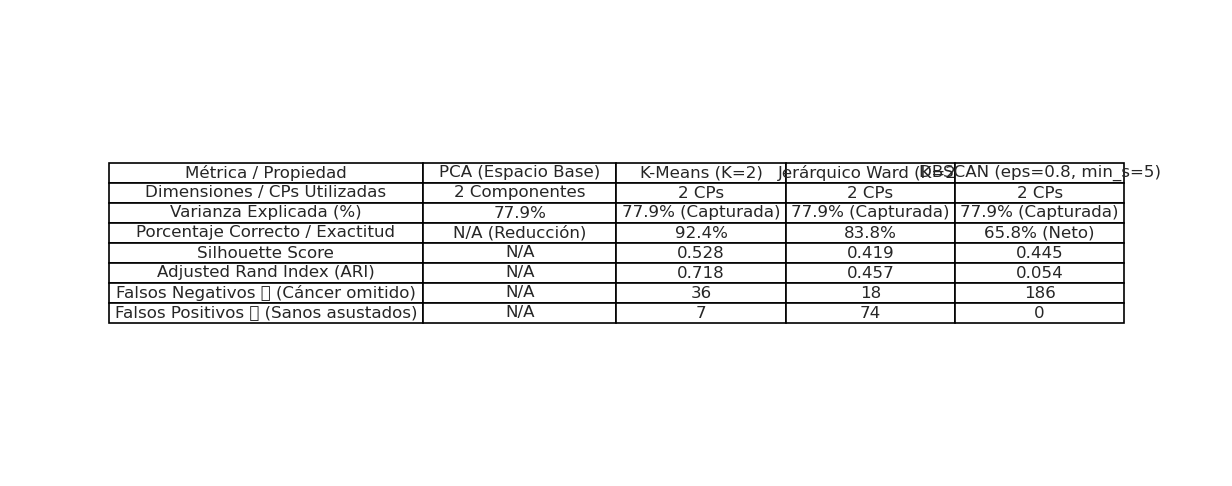

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Crear el diccionario estructurando el espacio PCA como la base de referencia
datos_exactos = {
    'Métrica / Propiedad': [
        'Dimensiones / CPs Utilizadas',
        'Varianza Explicada (%)',
        'Porcentaje Correcto / Exactitud', 
        'Silhouette Score', 
        'Adjusted Rand Index (ARI)', 
        'Falsos Negativos 🚨 (Cáncer omitido)', 
        'Falsos Positivos 🩹 (Sanos asustados)'
    ],
    'PCA (Espacio Base)': ['2 Componentes', '77.9%', 'N/A (Reducción)', 'N/A', 'N/A', 'N/A', 'N/A'],
    'K-Means (K=2)': ['2 CPs', '77.9% (Capturada)', '92.4%', '0.528', '0.718', '36', '7'],
    'Jerárquico Ward (K=2)': ['2 CPs', '77.9% (Capturada)', '83.8%', '0.419', '0.457', '18', '74'],
    'DBSCAN (eps=0.8, min_s=5)': ['2 CPs', '77.9% (Capturada)', '65.8% (Neto)', '0.445', '0.054', '186', '0']
}

# 2. Convertir a DataFrame de Pandas
df_completo = pd.DataFrame(datos_exactos)

# 3. Imprimir el formato limpio en consola/notebook
print("=================================================================================================================")
print("CUADRO INTEGRAL DEL ANÁLISIS NO SUPERVISADO (SOLO VARIABLES 'WORST')")
print("=================================================================================================================")
print(df_completo.to_string(index=False))
print("=================================================================================================================\n")

# 4. GENERAR REPORTE VISUAL FORMAL CON MATPLOTLIB
fig, ax = plt.subplots(figsize=(13, 5))
ax.axis('off')

# Crear la tabla gráfica en el lienzo
tabla_grafica = ax.table(
    cellText=df_completo.values, 
    colLabels=df_completo.columns, 
    loc='center', 
    cellLoc='center',
    colWidths=[0.26, 0.16, 0.14, 0.14, 0.14, 0.16]
)

# Estilización avanzada de celdas
tabla_grafica.auto_set_font_size(False)
tabla_grafica.set_font_size(10)
tabla_grafica.scale(1.1, 2.1) # Altura optimizada para lectura profesional

# Aplicar color institucional a las cabeceras (Azul pizarra oscuro)
for j in range(len(df_completo.columns)):
    celda_cabecera = tabla_grafica[0, j]
    celda_cabecera.set_text_props(weight='bold', color='white')
    celda_cabecera.set_facecolor('#2c3e50')

# Estilo para la primera columna de nombres de métricas
for i in range(1, len(df_completo) + 1):
    tabla_grafica[i, 0].set_text_props(weight='bold', ha='left')
    # Resaltar la columna de PCA en un tono gris suave para indicar que es la base matemática
    tabla_grafica[i, 1].set_facecolor('#f8f9fa')
    tabla_grafica[i, 1].set_text_props(style='italic')

plt.title('Evaluación de Modelos de Clustering sobre el Espacio Reducido PCA (10 Variables "Worst")', 
          fontsize=13, fontweight='bold', pad=25, color='#2c3e50')

plt.tight_layout()
# plt.savefig('tabla_final_pca_clustering.png', dpi=300, bbox_inches='tight')
plt.show()

Los mejores algoritmos, en base a los valores de las metricas de performance, son K means y Ward. Sin embargo, ambos incluyen muchos falsos negativos.
DBSCAN arrojan la conclusión teórica que el cáncer de mama no se distribuye en clusters delimitados por vacíos de densidad

### Conclusion final

- El primer gran acierto metodológico radica en la reducción dimensional. Al aislar las variables _worst, la transformación lineal de PCA condensó un problema original de 10 dimensiones en un espacio bidimensional plano (2 CPs) reteniendo una masiva varianza explicada del 77.9%.

- K-Means es el ganador estadístico indiscutido: Al registrar la mayor exactitud (92.4%), el Silhouette más alto (0.528) y un ARI de 0.718, demuestra una concordancia estructural casi perfecta con la patología.

- Jerárquico Ward es el ganador en seguridad clínica: Aunque su precisión global cae al 83.8% debido a que genera muchos falsos positivos (74), el método de Ward logra un hito crítico en medicina: reduce los Falsos Negativos a la mitad (solo 18 frente a los 36 de K-Means). Al priorizar la minimización de la varianza interna, Ward extiende preventivamente el diámetro del cluster maligno.

RECOMENDACION CLINICA: Si el sistema se diseñara como una herramienta de soporte médico hospitalario, el pipeline óptimo no debería usar un solo modelo. La recomendación es un enfoque híbrido o secuencial: usar el espacio PCA (2 CPs) como base, aplicar Clustering Jerárquico Ward en una primera fase de tamizaje (screening) para capturar la mayor cantidad de casos de riesgo posibles gracias a su baja tasa de falsos negativos, y usar K-Means como validador de consistencia geométrica debido a su alta especificidad y compacidad. 